# Insurance Claim Prediction

Revised from Nivedha Sivakumar's saved learning project. Original intent and model families are retained.

## Review changes
- Updated pandas drop syntax
- Replaced row-order split and unused remainder with a stratified holdout
- Excluded billed charges because availability before a claim is unestablished
- Used training-fitted StandardScaler
- Added baseline, per-class metrics, ROC AUC and average precision
- Removed obsolete split descriptions and unverified coefficient conclusions

Data files are excluded from GitHub; use authorized local copies. Evaluation is educational and does not establish real-world suitability.

## Results and limitations

The revised held-out ROC AUC is 0.899 and average precision is 0.941, with a majority-class baseline accuracy of 58.5%. The target construction and feature observation timing are not verified. Charges were excluded; this remains a course-data experiment, not an underwriting or claim decision tool.

In [1]:
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11})

**Independent variables**

1. age : age of policyholder
2. sex: gender of policy holder (female=0, male=1)
3. bmi: Body mass index, ideally 18.5 to 25
4. children: number of children / dependents of policyholder
5. smoker: smoking state of policyholder (non-smoke=0;smoker=1) 
6. region: the residential area of policyholder in the US (northeast=0, northwest=1, southeast=2, southwest=3)
7. charges: individual medical costs billed by health insurance

**Target variable**

1. insuranceclaim - categorical variable (0,1)

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

 
from sklearn.linear_model import LogisticRegression

import warnings



In [3]:
insuranceDF = pd.read_csv('insurance2.csv')
print('Rows:', len(insuranceDF))

Rows: 1338


In [4]:
insuranceDF.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             1338 non-null   int64  
 1   sex             1338 non-null   int64  
 2   bmi             1338 non-null   float64
 3   children        1338 non-null   int64  
 4   smoker          1338 non-null   int64  
 5   region          1338 non-null   int64  
 6   charges         1338 non-null   float64
 7   insuranceclaim  1338 non-null   int64  
dtypes: float64(2), int64(6)
memory usage: 83.8 KB


                     age       sex       bmi  children    smoker    region  \
age             1.000000 -0.020856  0.109272  0.042469 -0.025019  0.002127   
sex            -0.020856  1.000000  0.046371  0.017163  0.076185  0.004588   
bmi             0.109272  0.046371  1.000000  0.012759  0.003750  0.157566   
children        0.042469  0.017163  0.012759  1.000000  0.007673  0.016569   
smoker         -0.025019  0.076185  0.003750  0.007673  1.000000 -0.002181   
region          0.002127  0.004588  0.157566  0.016569 -0.002181  1.000000   
charges         0.299008  0.057292  0.198341  0.067998  0.787251 -0.006208   
insuranceclaim  0.113723  0.031565  0.384198 -0.409526  0.333261  0.020891   

                 charges  insuranceclaim  
age             0.299008        0.113723  
sex             0.057292        0.031565  
bmi             0.198341        0.384198  
children        0.067998       -0.409526  
smoker          0.787251        0.333261  
region         -0.006208        0.02089

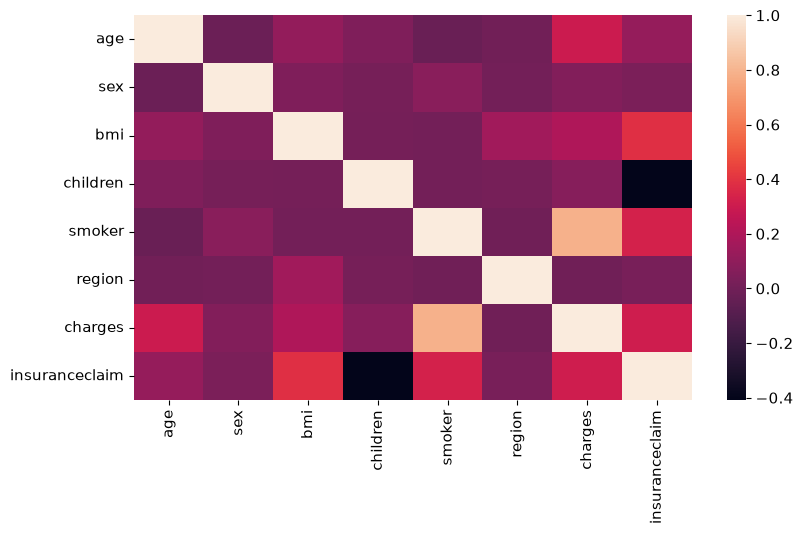

In [5]:
corr = insuranceDF.corr()
print(corr)
sns.heatmap(corr, 
        xticklabels=corr.columns,
        yticklabels=corr.columns)

In [6]:
from sklearn.model_selection import train_test_split
dfTrain, dfTest = train_test_split(insuranceDF, test_size=0.25, stratify=insuranceDF['insuranceclaim'], random_state=42)


In [7]:
trainLabel = dfTrain['insuranceclaim'].to_numpy()
trainData = dfTrain.drop(columns=['insuranceclaim', 'charges'])
testLabel = dfTest['insuranceclaim'].to_numpy()
testData = dfTest.drop(columns=['insuranceclaim', 'charges'])

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
preprocess = ColumnTransformer([
    ('numeric', StandardScaler(), ['age', 'bmi', 'children']),
    ('category', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), ['sex', 'smoker', 'region'])
])
trainData = preprocess.fit_transform(trainData)
testData = preprocess.transform(testData)

In [9]:
insuranceCheck = LogisticRegression(max_iter=2000, random_state=42)
insuranceCheck.fit(trainData, trainLabel)

Majority baseline accuracy: 0.5850746268656717
              precision    recall  f1-score   support

           0       0.84      0.83      0.84       139
           1       0.88      0.89      0.89       196

    accuracy                           0.87       335
   macro avg       0.86      0.86      0.86       335
weighted avg       0.87      0.87      0.87       335

ROC AUC: 0.8987299955953605
Average precision: 0.9406312465555348


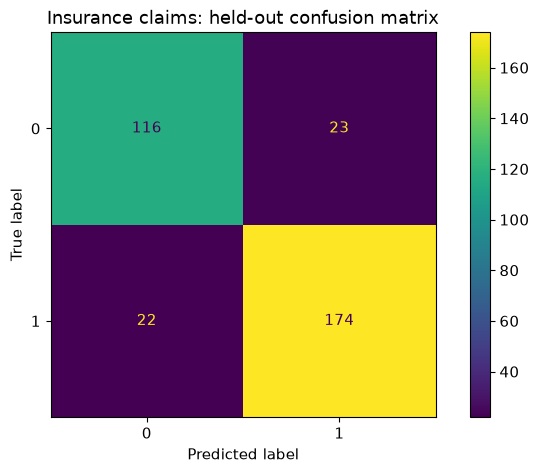

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, ConfusionMatrixDisplay
baseline = DummyClassifier(strategy='most_frequent').fit(trainData, trainLabel)
print('Majority baseline accuracy:', baseline.score(testData, testLabel))
prediction = insuranceCheck.predict(testData)
probability = insuranceCheck.predict_proba(testData)[:, 1]
print(classification_report(testLabel, prediction, zero_division=0))
print('ROC AUC:', roc_auc_score(testLabel, probability))
print('Average precision:', average_precision_score(testLabel, probability))
ConfusionMatrixDisplay.from_predictions(testLabel, prediction)
plt.title('Insurance claims: held-out confusion matrix')
plt.show()


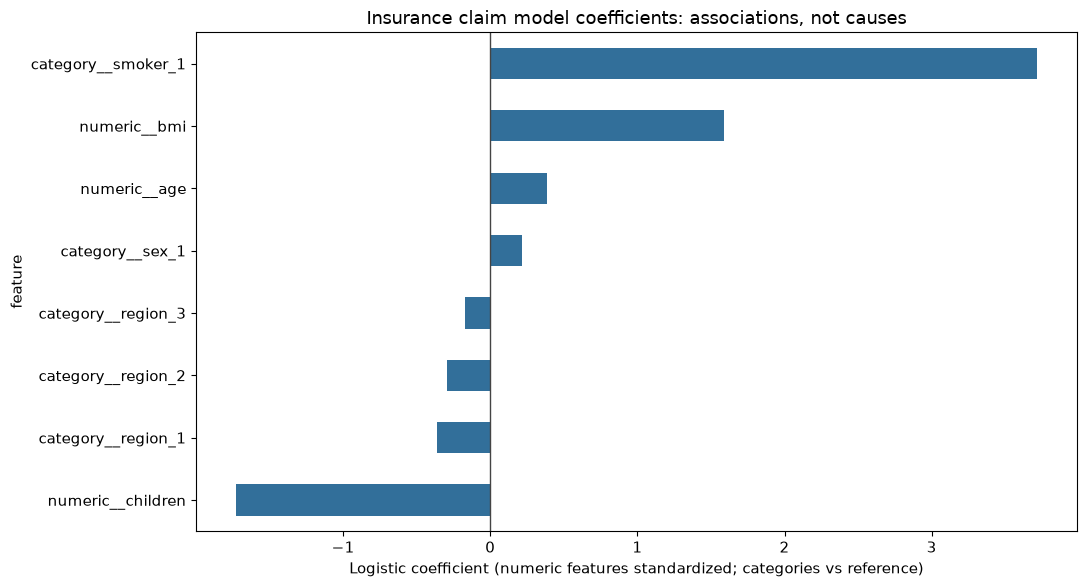

In [11]:
coeff = insuranceCheck.coef_[0]
labels = preprocess.get_feature_names_out()
features = pd.DataFrame({'feature': labels, 'coefficient': coeff}).sort_values('coefficient')
features.set_index('feature')['coefficient'].plot.barh(figsize=(11, 6), color='#326f9a')
plt.axvline(0, color='#444444', linewidth=1)
plt.xlabel('Logistic coefficient (numeric features standardized; categories vs reference)')
plt.title('Insurance claim model coefficients: associations, not causes')
plt.tight_layout()
plt.show()